# Linear Discriminant Analysis (LDA) with the Iris dataset

In this short exercise, you will use **Linear Discriminant Analysis (LDA)** to classify iris flowers into three species.

The **Iris dataset** contains 150 flowers from three species:

- *Iris setosa*
- *Iris versicolor*
- *Iris virginica*

For each flower, four measurements are available:

- sepal length
- sepal width
- petal length
- petal width

The goal is to predict the **species** from these measurements.

## 1. Load and inspect the dataset

We use the Iris dataset directly from `scikit-learn`.

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

iris = load_iris(as_frame=True)

X = iris.data
y = iris.target

print(X.head())


print("Species:", iris.target_names)
print("Shape of X:", X.shape)

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
Species: ['setosa' 'versicolor' 'virginica']
Shape of X: (150, 4)


^$^


## 2. Split the data into training and test sets

Use **80% for training** and **20% for testing**.

`stratify=y` keeps approximately the same proportion of each iris species in both sets.

In [25]:
# STUDENT: fill in test_size

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,      # fill in
    random_state=43,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (120, 2)
Test set: (30, 2)


## 3. Train an LDA classifier

Create the model, fit it on the **training set**, then predict the classes of the **test set**.

In [26]:
model = LinearDiscriminantAnalysis()

# STUDENT: fill in the missing arguments
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

## 4. Evaluate the classifier

Use **accuracy** to measure the proportion of correctly classified flowers.

In [27]:
# STUDENT: fill in the two arguments
accuracy = accuracy_score(y_test, y_pred)

print(f"Test accuracy = {accuracy:.3f}")

Test accuracy = 0.967


### [Checkpoint LDA-2]

**Q4:** What does an accuracy of `0.97` mean?
-> It means that 97% of the flowers where correctly classified by the model in the test set

**Q5:** Why do we calculate accuracy on the test set rather than only on the training set?
-> Because we want to see how well the model generalize to new data and detect overfitting.

## 5. Visualize the data in the LDA space

LDA can also transform the original four measurements into new axes called **linear discriminants**.

These axes are chosen to separate the predefined classes as much as possible.

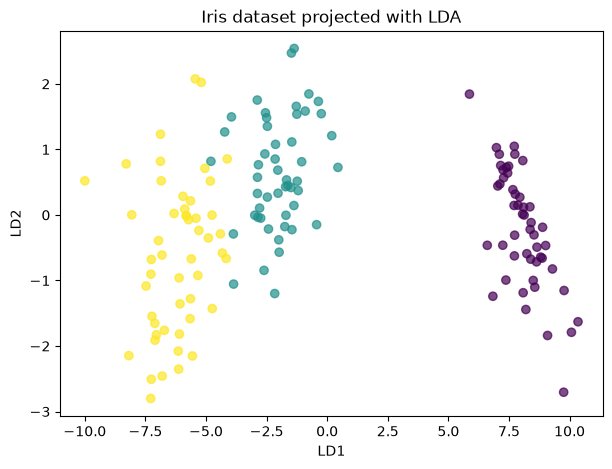

In [22]:
# Transform all observations into the LDA space
X_lda = model.transform(X)

plt.figure(figsize=(7, 5))

plt.scatter(
    X_lda[:, 0],
    X_lda[:, 1],
    c=y,
    alpha=0.7
)

plt.xlabel("LD1")
plt.ylabel("LD2")
plt.title("Iris dataset projected with LDA")
plt.show()

### [Checkpoint LDA-3]

**Q6:** What does each point in the LDA plot represent?
-> Each point is one flower projected in the LDA space. Each color refers to a specific class.

**Q7:** Which iris species appears easiest to separate from the others?
-> The violet ones

**Q8:** What is the main difference between the original four measurements and the new axes `LD1` and `LD2`?
-> LD1 and LD2 are created by LDA to maximise the class separation

**Q9:** In this example, what are the two main roles of LDA?
-> classification and dimensionality reduction (4 to 2)

## Optional challenge

Try training the LDA model with only two features:

```python
features = ["petal length (cm)", "petal width (cm)"]
```


Does the test accuracy change?

In [29]:

X = iris.data[["petal length (cm)","petal width (cm)"]] #selecting only the two petal features for training
y = iris.target

print(X.head())
print("Shape of X:", X.shape)

   petal length (cm)  petal width (cm)
0                1.4               0.2
1                1.4               0.2
2                1.3               0.2
3                1.5               0.2
4                1.4               0.2
Shape of X: (150, 2)


In [30]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,      
    random_state=43,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

model = LinearDiscriminantAnalysis()


model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Test accuracy = {accuracy:.3f}")

Training set: (120, 2)
Test set: (30, 2)
Test accuracy = 0.967


The accuracy does not chang
Maybe because the petal features already carry most of the information needed to separate the species.